# Roundness filter with west/east holdout

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seafloor as sf

lon, lat, z, ship, dx, dy = sf.load_clean()
d = sf.detect_peaks(z, dx, dy, lat, lon)
cat = sf.load_catalog(lon, lat)
print(f"{len(d['h'])} candidate peaks, {len(cat['lat'])} catalog seamounts")

854 candidate peaks, 118 catalog seamounts


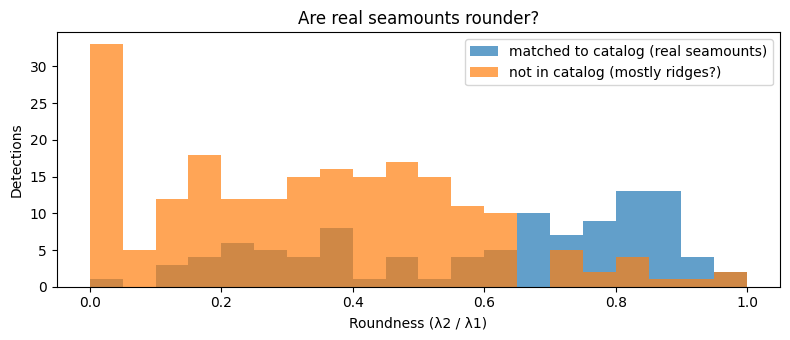

Median roundness: matched 0.68, unmatched 0.34


In [2]:
def score(keep, c_keep=None):
    c_keep = np.ones(len(cat["lat"]), bool) if c_keep is None else c_keep
    dm, cm = sf.match(d["lat"][keep], d["lon"][keep], cat["lat"][c_keep], cat["lon"][c_keep])
    P = dm.mean() if len(dm) else np.nan; R = cm.mean() if len(cm) else np.nan
    return P, R, 2 * P * R / (P + R) if P + R > 0 else np.nan, keep.sum()

base = d["h"] >= 1100
dm, _ = sf.match(d["lat"][base], d["lon"][base], cat["lat"], cat["lon"])
rb = d["round"][base]
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 21)
ax.hist(rb[dm], bins, alpha=0.7, label="matched to catalog (real seamounts)")
ax.hist(rb[~dm], bins, alpha=0.7, label="not in catalog (mostly ridges?)")
ax.set(xlabel="Roundness (λ2 / λ1)", ylabel="Detections", title="Are real seamounts rounder?"); ax.legend()
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "08_roundness_hist.png", dpi=200); plt.show()
print(f"Median roundness: matched {np.median(rb[dm]):.2f}, unmatched {np.median(rb[~dm]):.2f}")

 cutoff  kept  precision  recall    F1
    0.0   310       0.34    0.88  0.49
    0.1   271       0.38    0.87  0.53
    0.2   234       0.42    0.83  0.56
    0.3   199       0.44    0.75  0.56
    0.4   156       0.47    0.63  0.54
    0.5   119       0.59    0.59  0.59
    0.6    88       0.74    0.55  0.63
    0.7    63       0.79    0.42  0.55
    0.8    40       0.80    0.27  0.41


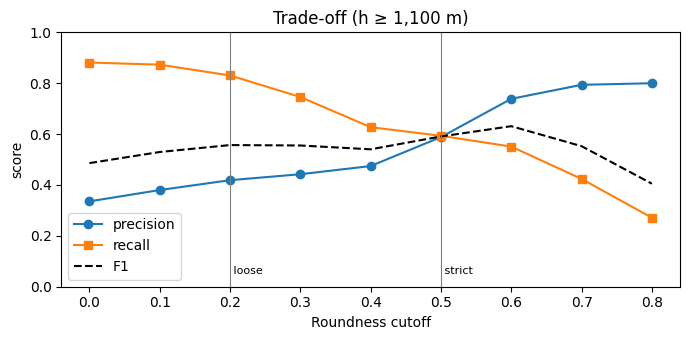

In [3]:
R_CUTS = np.round(np.arange(0, 0.81, 0.1), 1)
rows = [(r,) + score(base & (d["round"] >= r)) for r in R_CUTS]
print(f"{'cutoff':>7s}{'kept':>6s}{'precision':>11s}{'recall':>8s}{'F1':>6s}")
for r, P, R, F, n in rows: print(f"{r:7.1f}{n:6d}{P:11.2f}{R:8.2f}{F:6.2f}")
rows = np.array(rows)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rows[:, 0], rows[:, 1], "o-", label="precision"); ax.plot(rows[:, 0], rows[:, 2], "s-", label="recall"); ax.plot(rows[:, 0], rows[:, 3], "k--", label="F1")
for x, name in [(0.2, "loose"), (0.5, "strict")]: ax.axvline(x, c="gray", lw=0.8); ax.text(x, 0.05, f" {name}", fontsize=8)
ax.set(xlabel="Roundness cutoff", ylabel="score", title="Trade-off (h ≥ 1,100 m)", ylim=(0, 1)); ax.legend()
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "08_tradeoff.png", dpi=200); plt.show()

In [4]:
MID = 144.0
west_d, east_d = d["lon"] < MID, d["lon"] >= MID
west_c, east_c = cat["lon"] < MID, cat["lon"] >= MID
print(f"West: {west_c.sum()} catalog seamounts | East: {east_c.sum()}")

best = None
for h in range(500, 2001, 100):
    for r in R_CUTS:
        P, R, F, n = score(west_d & (d["h"] >= h) & (d["round"] >= r), west_c)
        if np.isfinite(F) and (best is None or F > best[2]): best = (h, r, F)
h_best, r_best, f_west = best
print(f"Tuned on west: h ≥ {h_best} m, roundness ≥ {r_best}  (west F1 = {f_west:.2f})\n")

options = {"No roundness": (1100, 0.0), "Loose": (1100, 0.2), "Strict": (1100, 0.5), "Data-decided": (h_best, r_best)}
print(f"{'option':22s}{'h_min':>7s}{'round':>7s}{'precision':>11s}{'recall':>8s}{'F1':>6s}   (EAST half, unseen)")
east_scores = {}
for name, (h, r) in options.items():
    P, R, F, n = score(east_d & (d["h"] >= h) & (d["round"] >= r), east_c)
    east_scores[name] = (P, R, F)
    print(f"{name:22s}{h:7d}{r:7.1f}{P:11.2f}{R:8.2f}{F:6.2f}")
print(f"\nData-decided: F1 on west (seen) {f_west:.2f} vs east (unseen) {east_scores['Data-decided'][2]:.2f}")

West: 66 catalog seamounts | East: 52
Tuned on west: h ≥ 1100 m, roundness ≥ 0.6  (west F1 = 0.69)

option                  h_min  round  precision  recall    F1   (EAST half, unseen)
No roundness             1100    0.0       0.31    0.87  0.46
Loose                    1100    0.2       0.39    0.83  0.53
Strict                   1100    0.5       0.50    0.52  0.51
Data-decided             1100    0.6       0.66    0.48  0.56

Data-decided: F1 on west (seen) 0.69 vs east (unseen) 0.56


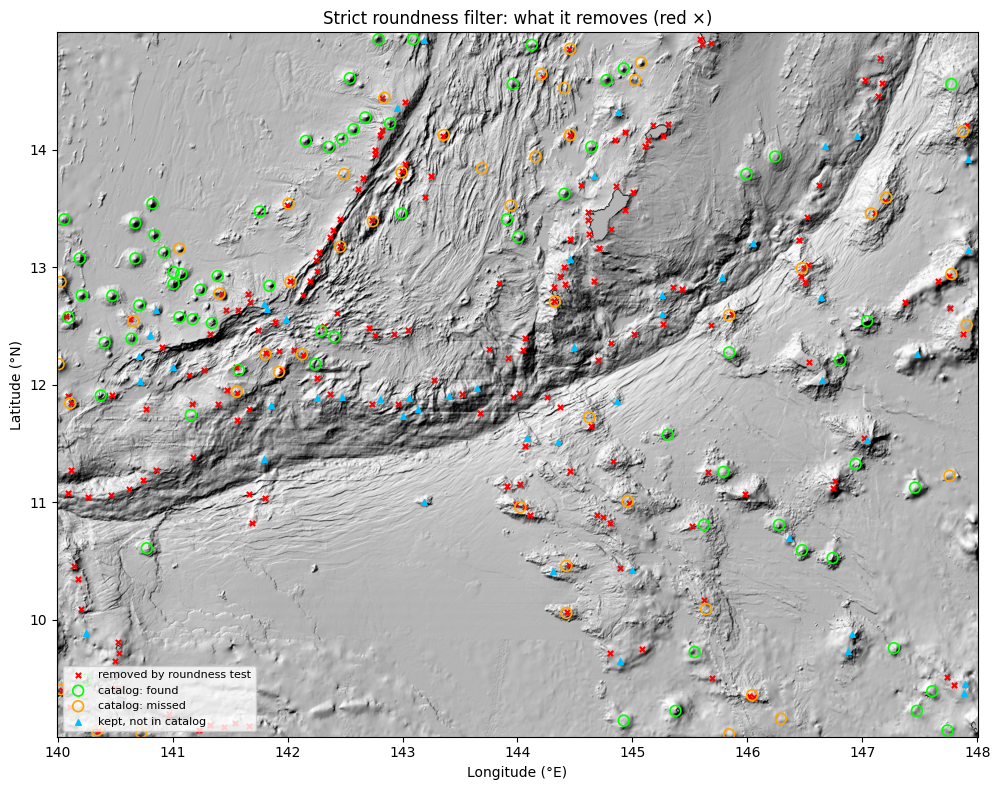

In [5]:
h_use, r_use = options["Strict"]
keep = (d["h"] >= h_use) & (d["round"] >= r_use)
dm, cm = sf.match(d["lat"][keep], d["lon"][keep], cat["lat"], cat["lon"])
shade = sf.hillshade(np.where(np.isnan(z), np.nanmedian(z), z), dx, dy)
extent = [lon[0], lon[-1], lat[0], lat[-1]]; aspect = 1 / np.cos(np.deg2rad(lat.mean()))
removed = base & ~keep
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(shade, extent=extent, origin="lower", cmap="gray", aspect=aspect)
ax.scatter(d["lon"][removed], d["lat"][removed], s=14, c="red", marker="x", label="removed by roundness test")
ax.scatter(cat["lon"][cm], cat["lat"][cm], s=60, facecolors="none", edgecolors="lime", lw=1.2, label="catalog: found")
ax.scatter(cat["lon"][~cm], cat["lat"][~cm], s=60, facecolors="none", edgecolors="orange", lw=1.2, label="catalog: missed")
ax.scatter(d["lon"][keep][~dm], d["lat"][keep][~dm], s=16, c="deepskyblue", marker="^", label="kept, not in catalog")
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)", title="Strict roundness filter: what it removes (red ×)")
ax.legend(loc="lower left", fontsize=8); fig.tight_layout(); fig.savefig(sf.FIG_DIR / "08_map.png", dpi=200); plt.show()

In [6]:
print("KEY NUMBERS")
print(f"  Median roundness: matched {np.median(rb[dm_b]) if (dm_b := sf.match(d['lat'][base], d['lon'][base], cat['lat'], cat['lon'])[0]).any() else float('nan'):.2f}, "
      f"unmatched {np.median(rb[~dm_b]):.2f}")
for name, (P, R, F) in east_scores.items():
    print(f"  EAST half, {name:22s}: precision {P:.2f}, recall {R:.2f}, F1 {F:.2f}")
print(f"  Data-decided cutoffs: h ≥ {h_best} m, roundness ≥ {r_best}; F1 west {f_west:.2f} → east {east_scores['Data-decided'][2]:.2f}")

KEY NUMBERS
  Median roundness: matched 0.68, unmatched 0.34
  EAST half, No roundness          : precision 0.31, recall 0.87, F1 0.46
  EAST half, Loose                 : precision 0.39, recall 0.83, F1 0.53
  EAST half, Strict                : precision 0.50, recall 0.52, F1 0.51
  EAST half, Data-decided          : precision 0.66, recall 0.48, F1 0.56
  Data-decided cutoffs: h ≥ 1100 m, roundness ≥ 0.6; F1 west 0.69 → east 0.56
